# Olist E-Commerce Customer Purchasing Behavior Analysis

## Objective
Analyze customer purchasing behavior using the Olist e-commerce dataset, focusing on repeat purchases, customer locations, monthly order trends, product categories, average order value (AOV), and RFM customer segmentation.

## Data
The analysis uses five local CSV files stored in the project's `data/` directory.

In [24]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load datasets
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
category_translation = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv"
)

print("Datasets loaded successfully.")
print(f"Customers: {customers.shape}")
print(f"Orders: {orders.shape}")
print(f"Order items: {order_items.shape}")
print(f"Products: {products.shape}")
print(f"Category translations: {category_translation.shape}")


Datasets loaded successfully.
Customers: (99441, 5)
Orders: (99441, 8)
Order items: (112650, 7)
Products: (32951, 9)
Category translations: (71, 2)


In [25]:

datasets = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "products": products,
    "category_translation": category_translation,
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print(f"{'=' * 60}")
    print("Columns:", df.columns.tolist())
    print("Duplicate rows:", df.duplicated().sum())
    print("\nMissing values:")
    print(df.isna().sum()[df.isna().sum() > 0])
    print("\nData types:")
    print(df.dtypes)



DATASET: customers
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Duplicate rows: 0

Missing values:
Series([], dtype: int64)

Data types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: orders
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
Duplicate rows: 0

Missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Data types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_

In [26]:

# Convert timestamp columns to datetime
timestamp_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in timestamp_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Inspect order statuses
print("Order status counts:")
print(orders["order_status"].value_counts(dropna=False))

print("\nPurchase timestamps:")
print("Missing or invalid purchase timestamps:",
      orders["order_purchase_timestamp"].isna().sum())

print("\nDuplicate order IDs:", orders["order_id"].duplicated().sum())

print("\nPurchase timestamp range:")
print("Earliest:", orders["order_purchase_timestamp"].min())
print("Latest:  ", orders["order_purchase_timestamp"].max())

print("\nDelivered orders:",
      (orders["order_status"] == "delivered").sum())


Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Purchase timestamps:
Missing or invalid purchase timestamps: 0

Duplicate order IDs: 0

Purchase timestamp range:
Earliest: 2016-09-04 21:15:19
Latest:   2018-10-17 17:30:18

Delivered orders: 96478


In [27]:

# Keep delivered orders with valid purchase timestamps.
# Drop duplicate order IDs defensively before customer-level analysis.
eligible_orders = (
    orders.loc[
        (orders["order_status"] == "delivered")
        & orders["order_purchase_timestamp"].notna()
    ]
    .drop_duplicates(subset="order_id")
    .copy()
)

# Attach customer identifiers
customer_orders = eligible_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one",
)

# Count distinct orders for each underlying customer
orders_per_customer = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
    .rename("order_count")
)

total_customers = len(orders_per_customer)
repeat_customers = int((orders_per_customer >= 2).sum())
one_time_customers = int((orders_per_customer == 1).sum())

repeat_rate = (
    repeat_customers / total_customers * 100
    if total_customers else 0
)

average_orders = (
    orders_per_customer.mean()
    if total_customers else 0
)

customer_metrics = pd.DataFrame({
    "Metric": [
        "Eligible delivered orders",
        "Unique customers",
        "Repeat customers",
        "One-time customers",
        "Repeat customer rate (%)",
        "Average orders per customer",
    ],
    "Value": [
        len(eligible_orders),
        total_customers,
        repeat_customers,
        one_time_customers,
        round(repeat_rate, 2),
        round(average_orders, 3),
    ],
})

display(customer_metrics)


,Metric,Value
0,Eligible delivered orders,96478.000
1,Unique customers,93358.000
2,Repeat customers,2801.000
3,One-time customers,90557.000
4,Repeat customer rate (%),3.000
5,Average orders per customer,1.033


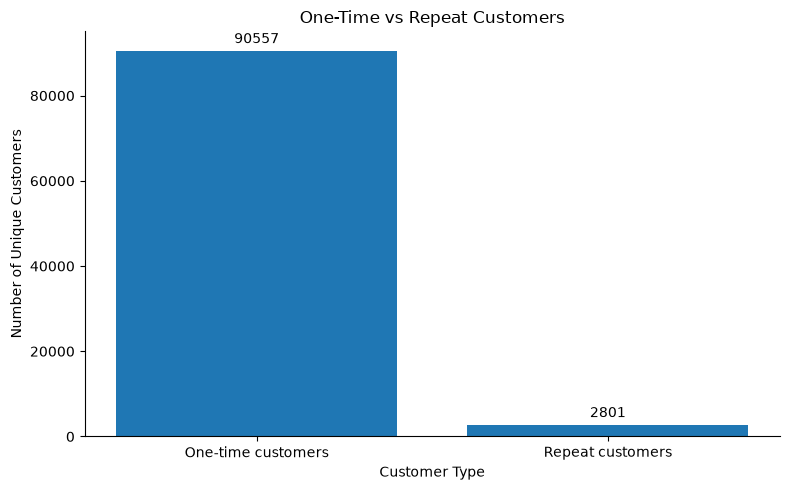

Chart saved to: c:\Users\lenovo\Documents\Data-Analytics-Project\output\repeat_customers.png


In [28]:

# Prepare customer counts for plotting
repeat_summary = pd.Series({
    "One-time customers": one_time_customers,
    "Repeat customers": repeat_customers,
})

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    repeat_summary.index,
    repeat_summary.values,
)

ax.set_title("One-Time vs Repeat Customers")
ax.set_ylabel("Number of Unique Customers")
ax.set_xlabel("Customer Type")

# Display counts on top of bars
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

chart_path = OUTPUT_DIR / "repeat_customers.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {chart_path}")


In [29]:

# Attach location details to the eligible customer population
customer_locations = customer_orders.merge(
    customers[
        ["customer_id", "customer_unique_id", "customer_state", "customer_city"]
    ],
    on=["customer_id", "customer_unique_id"],
    how="left",
    validate="many_to_one",
)

# Count each unique customer only once per state
state_customers = (
    customer_locations[
        ["customer_unique_id", "customer_state"]
    ]
    .drop_duplicates()
    .groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

# Count each unique customer only once per city
city_customers = (
    customer_locations[
        ["customer_unique_id", "customer_city", "customer_state"]
    ]
    .drop_duplicates()
    .groupby(["customer_city", "customer_state"])["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 states by unique customers:")
display(state_customers.head(10).rename("unique_customers").reset_index())

print("\nTop 10 cities by unique customers:")
display(city_customers.head(10).rename("unique_customers").reset_index())



Top 10 states by unique customers:


,customer_state,unique_customers
0,SP,39156
1,RJ,11917
2,MG,11001
3,RS,5168
4,PR,4769
5,SC,3449
6,BA,3158
7,DF,2019
8,ES,1928
9,GO,1895



Top 10 cities by unique customers:


,customer_city,customer_state,unique_customers
0,sao paulo,SP,14528
1,rio de janeiro,RJ,6361
2,belo horizonte,MG,2606
3,brasilia,DF,2013
4,curitiba,PR,1434
5,campinas,SP,1363
6,porto alegre,RS,1292
7,salvador,BA,1154
8,guarulhos,SP,1111
9,sao bernardo do campo,SP,881


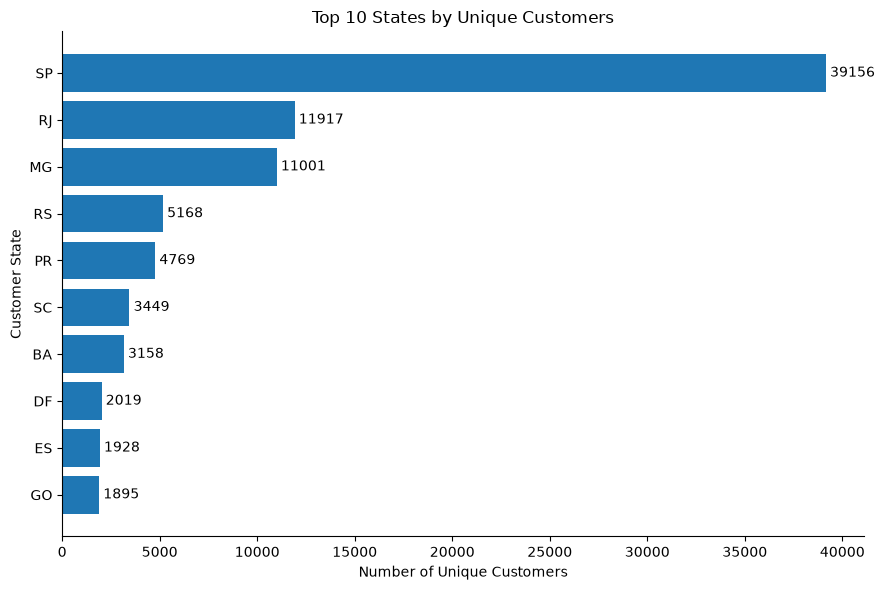

Chart saved to: c:\Users\lenovo\Documents\Data-Analytics-Project\output\top_customer_states.png


In [30]:

# Plot the 10 states with the most eligible unique customers
top_states = state_customers.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(top_states.index, top_states.values)

ax.set_title("Top 10 States by Unique Customers")
ax.set_xlabel("Number of Unique Customers")
ax.set_ylabel("Customer State")
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

state_chart_path = OUTPUT_DIR / "top_customer_states.png"
fig.savefig(state_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {state_chart_path}")


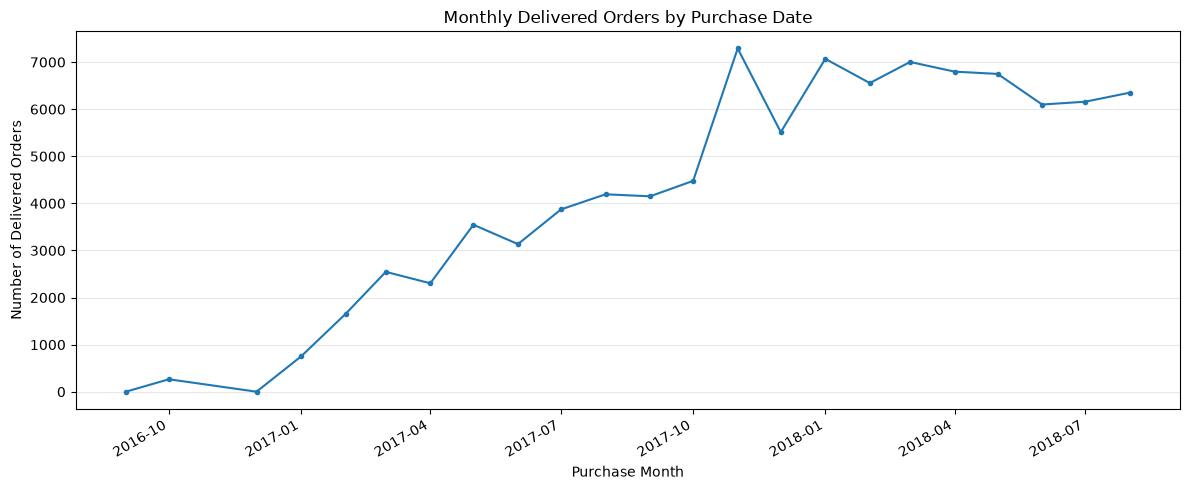

Chart saved to: c:\Users\lenovo\Documents\Data-Analytics-Project\output\monthly_order_trends.png

First and last five months:


,month,delivered_orders
0,2016-09,1
1,2016-10,265
2,2016-12,1
3,2017-01,750
4,2017-02,1653
18,2018-04,6798
19,2018-05,6749
20,2018-06,6099
21,2018-07,6159
22,2018-08,6351


In [31]:

# Group eligible delivered orders by purchase month
monthly_orders = (
    eligible_orders.assign(
        purchase_month=eligible_orders["order_purchase_timestamp"].dt.to_period("M")
    )
    .groupby("purchase_month")["order_id"]
    .nunique()
    .sort_index()
)

# Convert PeriodIndex to timestamps for plotting
monthly_dates = monthly_orders.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(monthly_dates, monthly_orders.values, marker="o", markersize=3)

ax.set_title("Monthly Delivered Orders by Purchase Date")
ax.set_xlabel("Purchase Month")
ax.set_ylabel("Number of Delivered Orders")
ax.grid(axis="y", alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()

monthly_chart_path = OUTPUT_DIR / "monthly_order_trends.png"
fig.savefig(monthly_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {monthly_chart_path}")

print("\nFirst and last five months:")
display(pd.DataFrame({
    "month": monthly_orders.index.astype(str),
    "delivered_orders": monthly_orders.values,
}).iloc[list(range(min(5, len(monthly_orders)))) +
         list(range(max(5, len(monthly_orders) - 5), len(monthly_orders)))])


In [32]:
# AOV = Total product value + freight value
# divided by the number of eligible delivered orders.
# Each order is counted once to avoid double-counting.
# Aggregate item prices and freight once per order
order_values = (
    order_items.groupby("order_id", as_index=False)
    .agg(
        product_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
    )
)

order_values["order_value"] = (
    order_values["product_value"] + order_values["freight_value"]
)

# Restrict AOV calculations to eligible delivered orders
eligible_order_values = eligible_orders[["order_id"]].merge(
    order_values,
    on="order_id",
    how="left",
    validate="one_to_one",
)

eligible_order_values[
    ["product_value", "freight_value", "order_value"]
] = eligible_order_values[
    ["product_value", "freight_value", "order_value"]
].fillna(0)

total_product_value = eligible_order_values["product_value"].sum()
total_freight_value = eligible_order_values["freight_value"].sum()
total_order_value = eligible_order_values["order_value"].sum()
aov = (
    total_order_value / len(eligible_order_values)
    if len(eligible_order_values) else 0
)

aov_summary = pd.DataFrame({
    "Metric": [
        "Eligible delivered orders",
        "Total product value",
        "Total freight value",
        "Total order value (product + freight)",
        "Average order value (AOV)",
    ],
    "Value (BRL)": [
        len(eligible_order_values),
        round(total_product_value, 2),
        round(total_freight_value, 2),
        round(total_order_value, 2),
        round(aov, 2),
    ],
})

display(aov_summary)


,Metric,Value (BRL)
0,Eligible delivered orders,96478.00
1,Total product value,13221498.11
2,Total freight value,2198275.64
3,Total order value (product + freight),15419773.75
4,Average order value (AOV),159.83


Top 10 categories by product sales value:


,category,items_sold,product_sales
44,health_beauty,9465,1233131.72
73,watches_gifts,5859,1166176.98
8,bed_bath_table,10953,1023434.76
68,sports_leisure,8431,954852.55
16,computers_accessories,7644,888724.61
40,furniture_decor,8160,711927.69
50,housewares,6795,615628.69
21,cool_stuff,3718,610204.10
6,auto,4140,578966.65
72,toys,4030,471286.48


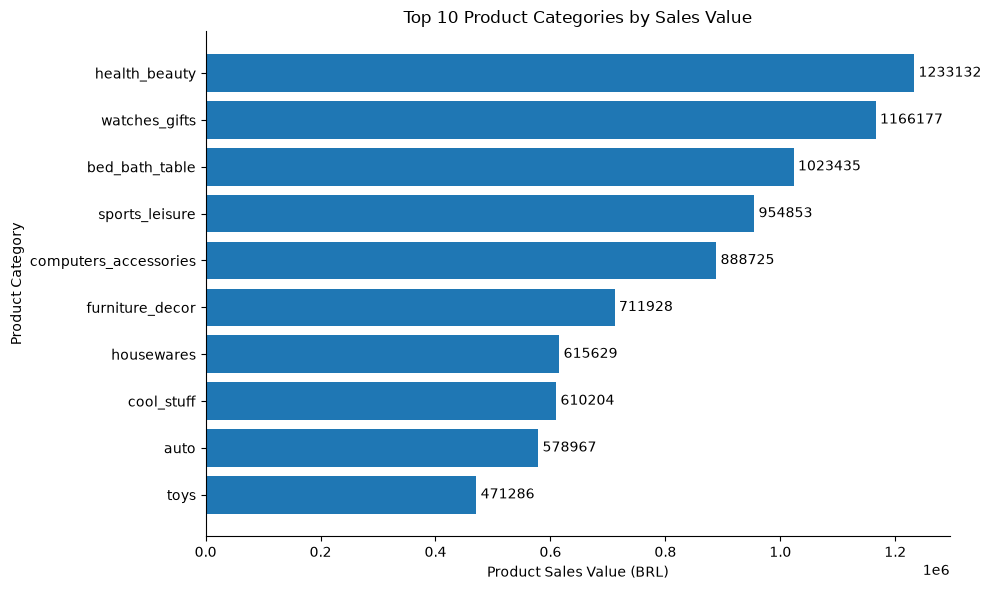

Chart saved to: c:\Users\lenovo\Documents\Data-Analytics-Project\output\top_product_categories.png


In [33]:

# Join order items to products and English category translations
items_with_categories = (
    order_items.merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left",
        validate="many_to_one",
    )
)

# Keep only items from eligible delivered orders
items_with_categories = items_with_categories.merge(
    eligible_orders[["order_id"]],
    on="order_id",
    how="inner",
    validate="many_to_one",
)

# Use English category labels; preserve unknown categories
items_with_categories["category"] = (
    items_with_categories["product_category_name_english"]
    .fillna(items_with_categories["product_category_name"])
    .fillna("Unknown")
)

# Category performance based on product price, excluding freight
category_sales = (
    items_with_categories.groupby("category", as_index=False)
    .agg(
        items_sold=("order_item_id", "size"),
        product_sales=("price", "sum"),
    )
    .sort_values("product_sales", ascending=False)
)

print("Top 10 categories by product sales value:")
display(category_sales.head(10))

top_categories = (
    category_sales.head(10)
    .sort_values("product_sales")
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_categories["category"],
    top_categories["product_sales"],
)

ax.set_title("Top 10 Product Categories by Sales Value")
ax.set_xlabel("Product Sales Value (BRL)")
ax.set_ylabel("Product Category")
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

category_chart_path = OUTPUT_DIR / "top_product_categories.png"
fig.savefig(category_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {category_chart_path}")


In [34]:
# Convert purchase timestamps into datetime format
eligible_orders["order_purchase_timestamp"] = pd.to_datetime(
    eligible_orders["order_purchase_timestamp"],
    errors="coerce"
)

# Remove any rows where timestamp conversion failed
eligible_orders = eligible_orders.dropna(
    subset=["order_purchase_timestamp"]
).copy()

print("Timestamp data type:")
print(eligible_orders["order_purchase_timestamp"].dtype)

print("Eligible orders:", len(eligible_orders))

Timestamp data type:
datetime64[ns]
Eligible orders: 96478


In [35]:
# Calculate product value and freight for each order
order_values = (
    order_items.groupby("order_id", as_index=False)
    .agg(
        product_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
)

# Calculate total order value
order_values["order_value"] = (
    order_values["product_value"] + order_values["freight_value"]
)

# Keep values for eligible delivered orders only
eligible_order_values = eligible_orders[["order_id"]].merge(
    order_values,
    on="order_id",
    how="left",
    validate="one_to_one"
)

eligible_order_values[
    ["product_value", "freight_value", "order_value"]
] = eligible_order_values[
    ["product_value", "freight_value", "order_value"]
].fillna(0)

# Map customer IDs to eligible orders
customer_orders = eligible_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Eligible order values:", len(eligible_order_values))
print("Customer orders:", len(customer_orders))

Eligible order values: 96478
Customer orders: 96478


In [36]:

# Reference date: one day after the latest eligible purchase
reference_date = (
    eligible_orders["order_purchase_timestamp"].max().normalize()
    + pd.Timedelta(days=1)
)

# Map each eligible order to its purchase timestamp
order_dates = eligible_orders[
    ["order_id", "order_purchase_timestamp"]
]

# Build order-level RFM input
rfm_orders = (
    eligible_order_values
    .merge(
        customer_orders[["order_id", "customer_unique_id"]],
        on="order_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        order_dates,
        on="order_id",
        how="left",
        validate="one_to_one",
    )
)

# Aggregate directly to customer level
rfm = (
    rfm_orders.groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_value", "sum"),
    )
)

rfm["recency_days"] = (
    reference_date - rfm["last_purchase"]
).dt.days

# Quintile scores; reverse recency so more recent customers score higher
rfm["R_score"] = pd.qcut(
    rfm["recency_days"].rank(method="first", ascending=True),
    5,
    labels=[5, 4, 3, 2, 1],
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5],
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5],
).astype(int)

# Vectorized, mutually exclusive segmentation
rfm["segment"] = "Other Customers"

needs_reengagement = rfm["R_score"] <= 2
frequent_high_spenders = (
    (rfm["F_score"] >= 4) & (rfm["M_score"] >= 4)
)
recent_frequent = (
    (rfm["R_score"] >= 4) & (rfm["F_score"] >= 4)
)

# Preserve priority: Recent and Frequent > Frequent High Spenders
# > Needs Re-engagement > Other Customers
rfm.loc[needs_reengagement, "segment"] = "Needs Re-engagement"
rfm.loc[frequent_high_spenders, "segment"] = "Frequent High Spenders"
rfm.loc[recent_frequent, "segment"] = "Recent and Frequent"

segment_summary = (
    rfm.groupby("segment", observed=True)
    .agg(
        customers=("frequency", "size"),
        average_monetary=("monetary", "mean"),
        average_frequency=("frequency", "mean"),
    )
    .sort_values("customers", ascending=False)
)

print("RFM reference date:", reference_date.date())
display(segment_summary.round(2))


RFM reference date: 2018-08-30


,customers,average_monetary,average_frequency
segment,,,
Other Customers,37953,150.19,1.00
Needs Re-engagement,31352,137.20,1.01
Recent and Frequent,14908,176.92,1.09
Frequent High Spenders,9145,304.03,1.15


In [37]:
print("Customer frequency distribution:")
print(rfm["frequency"].value_counts().sort_index())

print("\nFrequency score distribution:")
print(rfm["F_score"].value_counts().sort_index())

Customer frequency distribution:
frequency
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

Frequency score distribution:
F_score
1    18672
2    18671
3    18672
4    18671
5    18672
Name: count, dtype: int64


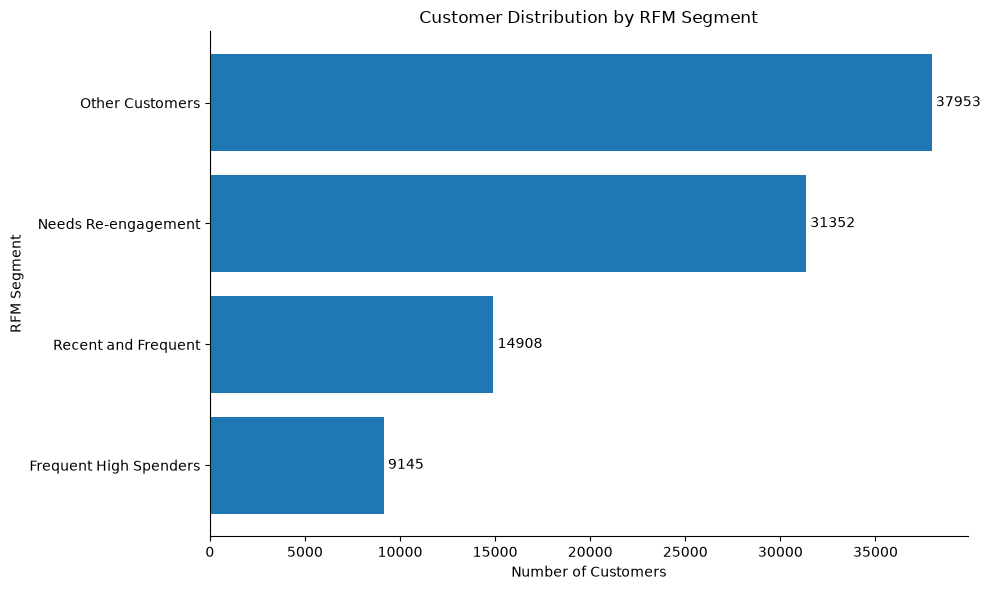

Chart saved to: c:\Users\lenovo\Documents\Data-Analytics-Project\output\rfm_customer_segments.png


In [38]:

fig, ax = plt.subplots(figsize=(10, 6))

segment_counts = segment_summary["customers"].sort_values()

bars = ax.barh(segment_counts.index, segment_counts.values)

ax.set_title("Customer Distribution by RFM Segment")
ax.set_xlabel("Number of Customers")
ax.set_ylabel("RFM Segment")
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()

rfm_chart_path = OUTPUT_DIR / "rfm_customer_segments.png"
fig.savefig(rfm_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {rfm_chart_path}")
